
# Customer Churn Prediction Using Ensemble Learning

## Datheon – Machine Learning & Data Science Internship

### Objective
To build and compare ensemble machine learning models
using the Telco Customer Churn dataset to predict
whether customers are likely to leave the service.

### Algorithms
1. Random Forest Classifier
2. XGBoost Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC Score
- Confusion Matrix
- Feature Importance


Libraries imported successfully!
Dataset loaded successfully!
Dataset Shape: (7043, 21)
Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   Int

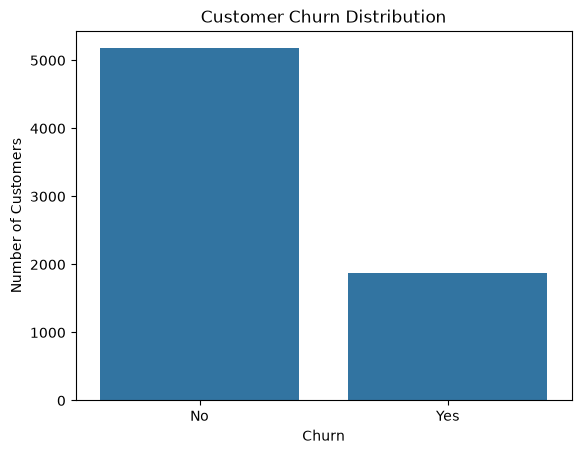

TotalCharges converted successfully!
Missing values in TotalCharges: 11
Missing values handled successfully!
Total missing values: 0
CustomerID column removed successfully!
Updated Dataset Shape: (7043, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             N

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7637,0.5437,0.6818,0.6050,0.8355
1,XGBoost,0.7708,0.5612,0.6257,0.5917,0.8371


,Model,Mean CV ROC-AUC
0,Random Forest,0.8403
1,XGBoost,0.8401


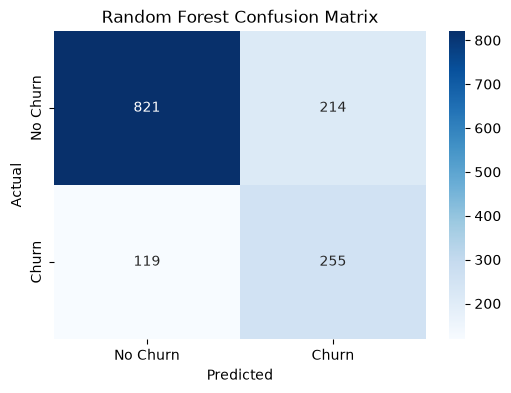

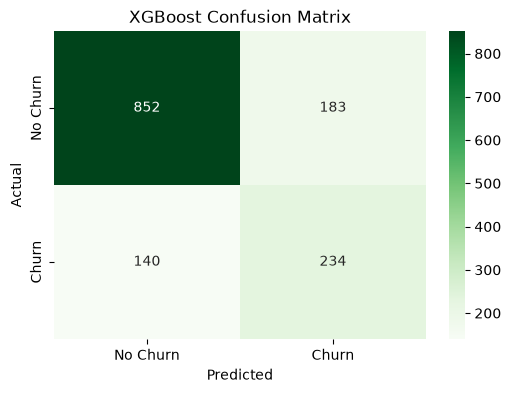

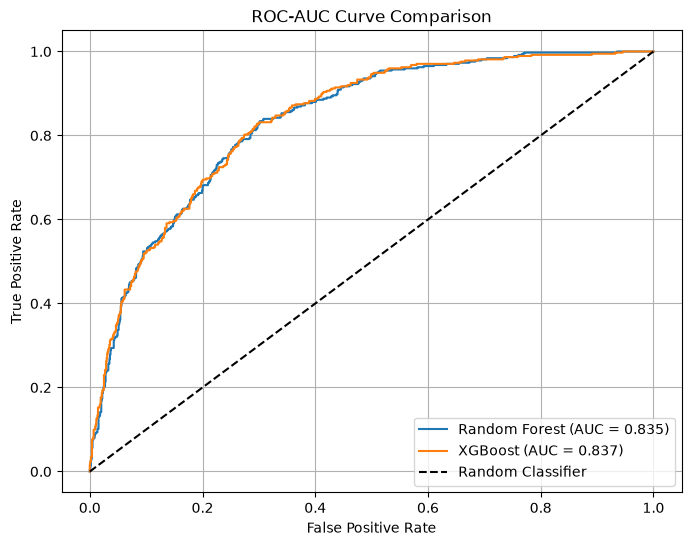

Random Forest ROC-AUC: 0.8355
XGBoost ROC-AUC: 0.8371
Total Features After Encoding: 45


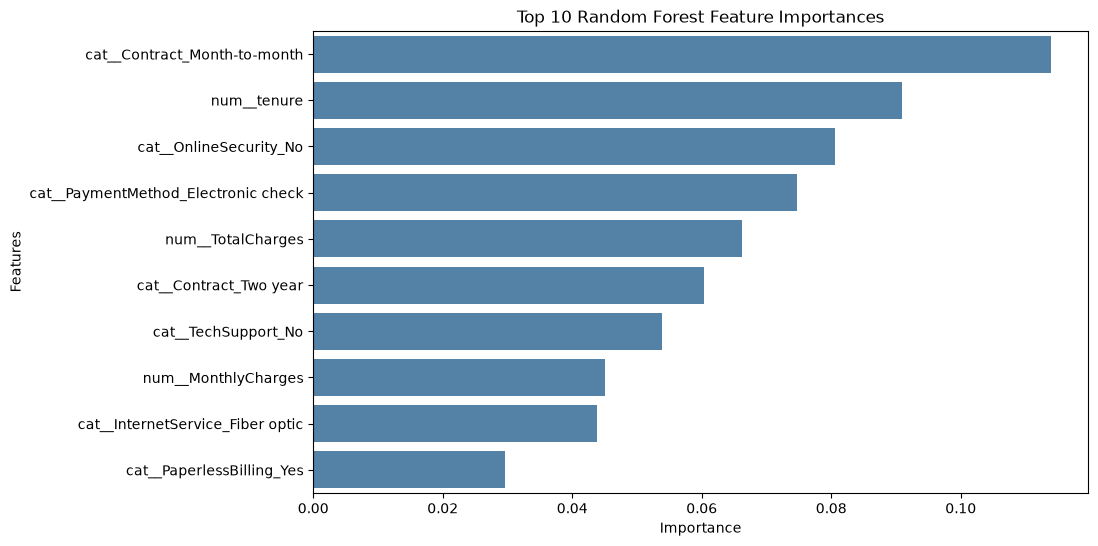

,Feature,Importance
36,cat__Contract_Month-to-month,0.113985
1,num__tenure,0.090925
18,cat__OnlineSecurity_No,0.080603
43,cat__PaymentMethod_Electronic check,0.074755
3,num__TotalCharges,0.066168
38,cat__Contract_Two year,0.060304
27,cat__TechSupport_No,0.053904
2,num__MonthlyCharges,0.045101
16,cat__InternetService_Fiber optic,0.043818
40,cat__PaperlessBilling_Yes,0.029640


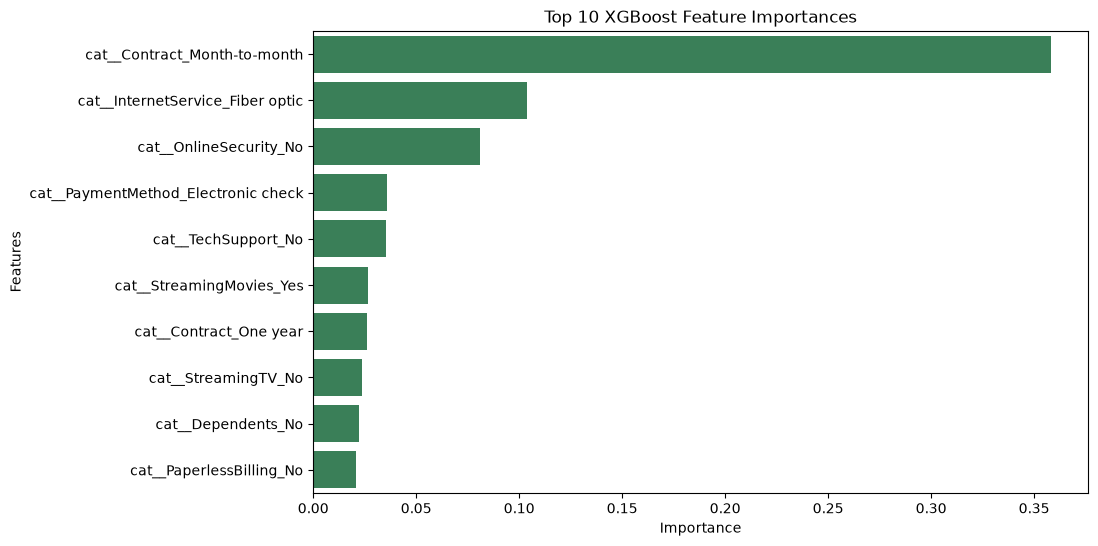

,Feature,Importance
36,cat__Contract_Month-to-month,0.358340
16,cat__InternetService_Fiber optic,0.103636
18,cat__OnlineSecurity_No,0.080739
43,cat__PaymentMethod_Electronic check,0.035647
27,cat__TechSupport_No,0.035466
35,cat__StreamingMovies_Yes,0.026783
37,cat__Contract_One year,0.025902
30,cat__StreamingTV_No,0.023884
8,cat__Dependents_No,0.022185
39,cat__PaperlessBilling_No,0.020596


Random Forest Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.79      0.83      1035
       Churn       0.54      0.68      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409


XGBoost Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.77      1409

FINAL MODEL COMPARISON
----------------------------------------


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7637,0.5437,0.6818,0.6050,0.8355
1,XGBoost,0.7708,0.5612,0.6257,0.5917,0.8371


,Model,Mean CV ROC-AUC
0,Random Forest,0.8403
1,XGBoost,0.8401


Best Model based on Test ROC-AUC: XGBoost
FINAL PROJECT RESULTS

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7637,0.5437,0.6818,0.6050,0.8355
1,XGBoost,0.7708,0.5612,0.6257,0.5917,0.8371


... (2 outputs left out)


Best Model: XGBoost

Top 5 Random Forest Features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.113985
1,num__tenure,0.090925
18,cat__OnlineSecurity_No,0.080603
43,cat__PaymentMethod_Electronic check,0.074755
3,num__TotalCharges,0.066168



Top 5 XGBoost Features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.358340
16,cat__InternetService_Fiber optic,0.103636
18,cat__OnlineSecurity_No,0.080739
43,cat__PaymentMethod_Electronic check,0.035647
27,cat__TechSupport_No,0.035466


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


print("Column Names:")
print(df.columns.tolist())


df.info()

df.describe()

print("Missing Values:")
print(df.isnull().sum())

print("Churn Distribution:")
print(df['Churn'].value_counts())

sns.countplot(data=df, x='Churn')
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("TotalCharges converted successfully!")
print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())

df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print("Missing values handled successfully!")
print("Total missing values:", df.isnull().sum().sum())

df.drop('customerID', axis=1, inplace=True)

print("CustomerID column removed successfully!")
print("Updated Dataset Shape:", df.shape)

print(df.head())

X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

print("Features and target separated successfully!")
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Features:", categorical_features)
print("\nNumerical Features:", numerical_features)


categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("SMOTE applied successfully!")

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())


rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest model trained successfully!")

rf_predictions = rf_model.predict(X_test_processed)

rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest predictions completed!")
print("First 10 Predictions:", rf_predictions[:10])

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train_balanced, y_train_balanced)

print("XGBoost model trained successfully!")

xgb_predictions = xgb_model.predict(X_test_processed)

xgb_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

print("XGBoost predictions completed!")
print("First 10 Predictions:", xgb_predictions[:10])

rf_cv_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=10
    ))
])

xgb_cv_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='logloss'
    ))
])

print("Cross-validation pipelines created successfully!")

rf_cv_scores = cross_val_score(
    rf_cv_pipeline, X_train, y_train,
    cv=5, scoring='roc_auc', n_jobs=-1
)

xgb_cv_scores = cross_val_score(
    xgb_cv_pipeline, X_train, y_train,
    cv=5, scoring='roc_auc', n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())

print("\nXGBoost CV Scores:", xgb_cv_scores)
print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

rf_results = {
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, rf_predictions),
    'Precision': precision_score(y_test, rf_predictions),
    'Recall': recall_score(y_test, rf_predictions),
    'F1-Score': f1_score(y_test, rf_predictions),
    'ROC-AUC': roc_auc_score(y_test, rf_probabilities)
}

xgb_results = {
    'Model': 'XGBoost',
    'Accuracy': accuracy_score(y_test, xgb_predictions),
    'Precision': precision_score(y_test, xgb_predictions),
    'Recall': recall_score(y_test, xgb_predictions),
    'F1-Score': f1_score(y_test, xgb_predictions),
    'ROC-AUC': roc_auc_score(y_test, xgb_probabilities)
}

results_df = pd.DataFrame([rf_results, xgb_results])

print("Model Performance Comparison:")
display(results_df.round(4))

cv_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Mean CV ROC-AUC': [
        rf_cv_scores.mean(),
        xgb_cv_scores.mean()
    ]
})

display(cv_results.round(4))

rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

xgb_cm = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

print("Random Forest ROC-AUC:", round(rf_auc, 4))
print("XGBoost ROC-AUC:", round(xgb_auc, 4))


feature_names = preprocessor.get_feature_names_out()

print("Total Features After Encoding:", len(feature_names))

rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance', ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_importance,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

display(rf_importance)


xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance', ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=xgb_importance,
    x='Importance',
    y='Feature',
    color='seagreen'
)

plt.title("Top 10 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

display(xgb_importance)
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=['No Churn', 'Churn']
))

print("\nXGBoost Classification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=['No Churn', 'Churn']
))

print("FINAL MODEL COMPARISON")
print("-" * 40)

display(results_df.round(4))
display(cv_results.round(4))

best_model = results_df.loc[
    results_df['ROC-AUC'].idxmax(), 'Model'
]

print("Best Model based on Test ROC-AUC:", best_model)

print("FINAL PROJECT RESULTS")
print("=" * 50)

print("\nModel Performance:")
display(results_df.round(4))

print("\nCross-Validation Results:")
display(cv_results.round(4))

print("\nBest Model:", best_model)

print("\nTop 5 Random Forest Features:")
display(rf_importance.head())

print("\nTop 5 XGBoost Features:")
display(xgb_importance.head())

## 17. Conclusion

In this project, Random Forest and XGBoost ensemble learning algorithms were implemented to predict customer churn using the Telco Customer Churn dataset.

The dataset was cleaned and preprocessed using numerical scaling and One-Hot Encoding. SMOTE was applied to balance the training data.

Both models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, confusion matrices, and cross-validation.

Feature importance analysis was also performed to identify the key factors associated with customer churn.

The project demonstrates how ensemble machine learning techniques can be used to analyze customer behaviour and predict customer churn.